# Estudo 09 – Ideias do professor: dois modelos, o alvo da previsão e "acertar pouco, ganhar muito"

Três ideias apresentadas em aula (05/11/2026), testadas com os nossos dados:

1. **Dois modelos, um para alta e outro para baixa**, porque os movimentos de alta e de baixa seriam "fundamentalmente diferentes"; e **entrar só quando os dois concordam**.
2. **O alvo errado:** minimizar o erro entre previsto e realizado faz o modelo "repetir o último valor", e a previsão parece a série **deslocada um passo à direita**. O professor defende buscar **correlação** com o alvo: as curvas podem ficar longe, desde que andem juntas.
3. **Acertar pouco e ganhar muito:** uma baixa taxa de acerto não é problema se os ganhos forem grandes e as perdas pequenas; a ideia seria detectar cenários com margem de ganho alta.

Para cada ideia: o que ela quer dizer estatisticamente, o que os nossos dados mostram e como usar.

**Dados:** desenvolvimento (WIN até 31/12/2024) e as previsões de 2024 já geradas pelas frentes estatística (ARIMA) e de ML (Random Forest), nos mesmos candles.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path
from scipy import stats

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA)); sys.path.append(str(PASTA / "frentes" / "estatistico"))
import tt1_comum as t
import custos as cu

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})
pd.set_option("display.width", 200)

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]

def ols_robusto(y, X):
    "Mínimos quadrados com erro-padrão robusto (HC0): devolve coeficientes, erros-padrão e matriz de covariância."
    b, *_ = np.linalg.lstsq(X, y, rcond=None); e = y - X @ b
    XtXi = np.linalg.inv(X.T @ X); V = XtXi @ (X.T * e ** 2) @ X @ XtXi
    return b, np.sqrt(np.diag(V)), V

## 1. Altas e baixas são "fundamentalmente diferentes"?

"Diferente" pode querer dizer quatro coisas, e cada uma pede um tipo de modelo:

| Sentido | Pergunta estatística | Modelo que captura |
|---|---|---|
| **Na direção (média)** | O próximo retorno reage diferente a uma alta e a uma baixa? | AR com limiar (TAR): coeficientes separados para retornos positivos e negativos |
| **Na forma (caudas)** | Quedas grandes são mais frequentes que altas grandes? ("sobe de escada, desce de elevador") | distribuições assimétricas |
| **Na volatilidade** | Uma queda aumenta a volatilidade futura mais que uma alta do mesmo tamanho? (**efeito alavancagem**) | GJR-GARCH, EGARCH, HAR com assimetria |
| **Em regimes** | Mercados em alta e em baixa têm parâmetros diferentes? | modelos de mudança de regime (Markov, Hamilton 1989) |

Um ARMA usa **o mesmo coeficiente** para altas e baixas, então não captura nenhuma dessas assimetrias. É uma justificativa estatística para "dois modelos".

### 1.1 Intradiário: direção, caudas e tamanho

Retornos de 5 e 60 min medidos em unidades da volatilidade recente (z, Estudo 05), para que dias calmos e agitados fiquem comparáveis. Para a direção, a regressão:

$$z_{t+1} = a + b^{+}\cdot \max(z_t, 0) + b^{-}\cdot \min(z_t, 0)$$

Se altas e baixas fossem diferentes na direção, b⁺ ≠ b⁻.

In [2]:
linhas = []
for k in [5, 60]:
    c = win.resample(f"{k}min").agg({"open": "first", "close": "last"}).dropna()
    d = pd.Series(c.index.normalize(), index=c.index)
    r = np.log(c.close).diff() * 100; r[d != d.shift()] = np.nan
    z = r / r.rolling({5: 48, 60: 20}[k], min_periods=10).std().shift(1)
    prox = z.shift(-1); prox[d.shift(-1) != d] = np.nan
    df = pd.DataFrame({"z": z, "prox": prox}).dropna()
    X = np.c_[np.ones(len(df)), df.z.clip(lower=0), df.z.clip(upper=0)]
    b, se, V = ols_robusto(df.prox.values, X)
    z_dif = (b[1] - b[2]) / np.sqrt(V[1, 1] + V[2, 2] - 2 * V[1, 2])
    alta, baixa = df[df.z > 2].prox.abs(), df[df.z < -2].prox.abs()
    linhas.append(dict(candle_min=k, b_alta=b[1], b_baixa=b[2], z_diferenca_direcao=z_dif,
                       quantil_1pct=df.z.quantile(0.01), quantil_99pct=df.z.quantile(0.99),
                       prox_apos_alta_grande=alta.mean(), prox_apos_baixa_grande=baixa.mean(),
                       z_diferenca_tamanho=(baixa.mean() - alta.mean()) / np.sqrt(alta.var() / len(alta) + baixa.var() / len(baixa))))
pd.DataFrame(linhas).set_index("candle_min").round(3).T

candle_min,5,60
b_alta,-0.006,-0.018
b_baixa,0.010,0.005
z_diferenca_direcao,-1.256,-0.770
quantil_1pct,-2.926,-3.081
quantil_99pct,2.907,3.146
prox_apos_alta_grande,1.137,0.923
prox_apos_baixa_grande,1.109,0.888
z_diferenca_tamanho,-1.076,-0.540


**Leitura:**

- **Direção:** b⁺ e b⁻ são estatisticamente iguais (|z| ≤ 1,3). O próximo retorno reage do mesmo jeito (isto é, quase nada) a altas e a baixas.
- **Caudas:** os quantis de 1% e 99% são simétricos (≈ −2,9 e +2,9 em 5 min; ≈ −3,1 e +3,1 em 60 min).
- **Tamanho do próximo movimento:** igual depois de altas e de baixas grandes (|z| ≤ 1,1).

No intradiário, **altas e baixas se comportam igual**. Bate com o Estudo 05 (H4).

### 1.2 Diário: o efeito alavancagem

Volatilidade realizada de amanhã em função da de hoje e do retorno de hoje, separado em alta e baixa (em unidades da volatilidade do próprio dia):

$$\ln \sigma_{d+1} = a + c\,\ln \sigma_d + b^{+}\cdot \text{alta}_d + b^{-}\cdot \text{baixa}_d$$

In [3]:
d1 = pd.Series(win.index.normalize(), index=win.index)
r1 = np.log(win.close).diff(); r1[d1 != d1.shift()] = np.nan
n1 = r1.groupby(d1).count()
rv = ((r1 ** 2).groupby(d1).sum() * 1e4)[n1 >= 400]                      # variância realizada (%²), pregões completos
sd = np.sqrt(rv)
rd = ((np.log(win.close).groupby(d1).last() - np.log(win.open).groupby(d1).first()) * 100).reindex(rv.index)
D = pd.DataFrame({"l": np.log(sd), "l_amanha": np.log(sd).shift(-1),
                  "alta": rd.clip(lower=0) / sd, "baixa": -rd.clip(upper=0) / sd}).dropna()
X = np.c_[np.ones(len(D)), D.l, D.alta, D.baixa]
b, se, V = ols_robusto(D.l_amanha.values, X)
z_dif = (b[3] - b[2]) / np.sqrt(V[2, 2] + V[3, 3] - 2 * V[2, 3])
print(f"efeito na volatilidade de amanhã, por 1 'desvio do dia': queda {100 * (np.exp(b[3]) - 1):+.1f}% · alta {100 * (np.exp(b[2]) - 1):+.1f}% "
      f"· diferença z = {z_dif:+.2f}")

efeito na volatilidade de amanhã, por 1 'desvio do dia': queda +7.3% · alta +4.0% · diferença z = +2.49


**Leitura:** um dia de queda aumenta a volatilidade do dia seguinte **mais** que um dia de alta do mesmo tamanho (+7,3% contra +4,0%; diferença significativa, z ≈ 2,5). É o **efeito alavancagem**, um dos fatos estilizados mais conhecidos dos mercados de ações.

**Conclusão da Seção 1:** nos nossos dados, altas e baixas **não** são diferentes na direção, mas **são** na volatilidade. Se a ideia de "dois modelos" for usada, o lugar natural é o modelo de **volatilidade** (por exemplo, um HAR ou GARCH com termos separados para quedas), não o de direção.

## 2. "Entrar só quando os dois concordam"

Uma leitura possível da ideia: dois modelos diferentes, e só operar quando ambos apontam a mesma direção. Quando isso funciona?

Se cada modelo acerta a direção com probabilidade p e os **erros são independentes**, entre os casos em que concordam:

$$P(\text{acerto} \mid \text{concordam}) = \frac{p^2}{p^2 + (1-p)^2}$$

In [4]:
p = np.array([0.50, 0.51, 0.52, 0.55, 0.60])
pd.DataFrame({"acerto de cada modelo": p, "acerto quando concordam": p ** 2 / (p ** 2 + (1 - p) ** 2),
              "fração dos candles em que concordam": p ** 2 + (1 - p) ** 2}).round(3)

,acerto de cada modelo,acerto quando concordam,fração dos candles em que concordam
0,0.50,0.500,0.500
1,0.51,0.520,0.500
2,0.52,0.540,0.501
3,0.55,0.599,0.505
4,0.60,0.692,0.520


- A concordância **amplifica** uma habilidade que já existe: dois modelos com 55% viram 60% quando concordam.
- Ela **não cria** habilidade: dois modelos com 50% continuam com 50%.
- Se os erros forem correlacionados (modelos parecidos, mesmos dados), o ganho é menor.
- O preço é operar em cerca de metade dos candles: menos operações, menos poder estatístico (Estudo 03).

**Com os nossos modelos:** ARIMA (frente estatística) e Random Forest (frente de ML), previsões de 2024 nos mesmos candles. A tabela mostra o "IC" de cada modelo (*information coefficient*: correlação entre a previsão e o retorno realizado), a correlação entre as previsões dos dois, as taxas de acerto e o custo de equilíbrio (Estudo 01) de operar pelo sinal de cada um e só quando concordam.

In [5]:
linhas = []
for candle in ["15min", "60min"]:
    for jan in [6, 12]:
        a = pd.read_csv(f"{PASTA}/resultados/estatistico/previsoes/WIN_{candle}_{jan}m_arima_val.csv", index_col=0, parse_dates=True)
        rf = pd.read_csv(f"{PASTA}/resultados/ml/previsoes/WIN_{candle}_{jan}m_rf_val.csv", index_col=0, parse_dates=True)
        assert (a.index == rf.index).all()
        y = a.y_true; sa, sr = np.sign(a.y_pred), np.sign(rf.y_pred)
        concordam = (sa == sr) & (sa != 0)
        def equilibrio(sinal):
            o = cu.simular(a.assign(y_pred=sinal), 0, None, None, "base"); o = o[o.lado != 0].bruto
            return f"{o.mean():+.1f} ± {o.std() / np.sqrt(len(o)):.1f}"
        acerto = lambda s, m: np.mean(np.sign(y[m]) == s[m])
        linhas.append({"candle": candle, "janela": f"{jan} m",
                       "IC do ARIMA": np.corrcoef(a.y_pred, y)[0, 1], "IC do RF": np.corrcoef(rf.y_pred, y)[0, 1],
                       "correlação entre os modelos": np.corrcoef(a.y_pred, rf.y_pred)[0, 1],
                       "acerto ARIMA": acerto(sa, sa != 0), "acerto RF": acerto(sr, sr != 0),
                       "fração em que concordam": concordam.mean(), "acerto quando concordam": acerto(sa, concordam),
                       "equilíbrio ARIMA (pts)": equilibrio(sa), "equilíbrio RF (pts)": equilibrio(sr),
                       "equilíbrio quando concordam (pts)": equilibrio(np.where(concordam, sa, 0))})
pd.DataFrame(linhas).set_index(["candle", "janela"]).round(3).T

candle                                  15min                   60min             
janela                                    6 m        12 m         6 m         12 m
IC do ARIMA                            -0.009      -0.009      -0.012       -0.036
IC do RF                                0.011       0.008      -0.022        0.008
correlação entre os modelos               0.1       0.065       0.091        0.066
acerto ARIMA                            0.489       0.485       0.498        0.474
acerto RF                               0.496       0.489       0.489        0.504
fração em que concordam                 0.564       0.554       0.518        0.534
acerto quando concordam                 0.493       0.485       0.492        0.484
equilíbrio ARIMA (pts)             -0.3 ± 1.6  -2.1 ± 1.6  +3.6 ± 6.2  -11.8 ± 6.2
equilíbrio RF (pts)                +0.6 ± 1.6  -0.5 ± 1.6  -9.3 ± 6.2   +6.1 ± 6.2
equilíbrio quando concordam (pts)  +0.3 ± 2.1  -2.3 ± 2.1  -5.6 ± 8.4   -5.4 ± 8.2

**Leitura:**

- As previsões dos dois modelos quase não se correlacionam (0,07–0,10). É a condição ideal para a concordância ajudar, porque os erros são quase independentes.
- Mas **nenhum dos dois tem habilidade**: IC entre −0,04 e +0,01, acerto de 47–50%. Quando concordam, o acerto continua em **48–49%**, e o custo de equilíbrio continua ≈ 0.
- A ideia é boa como **filtro de modelos que já acertam um pouco**. A pesquisa do professor provavelmente partia de modelos com alguma habilidade individual. Aqui não há o que amplificar.

## 3. O alvo da previsão: erro ou correlação?

### 3.1 Por que minimizar o erro "desloca a curva"

Minimizar o erro quadrático médio (MSE) leva à **média condicional**: o melhor palpite, em média, dado o passado. Numa série **persistente** (preço, volatilidade), o melhor palpite está muito perto do último valor. A previsão fica parecida com a série **atrasada um passo**: o deslocamento à direita que o professor descreveu e que aparece no gráfico do HAR (Estudo 07).

Isso não é um defeito do método: a informação nova chega depois. Mas mostra que **boa parte do acerto aparente é só persistência**. É por isso que o projeto prevê o **retorno** e não o preço: no retorno não há persistência para "copiar".

### 3.2 O MSE é cego para correlações pequenas

Para uma previsão f com correlação ρ com o alvo y, o MSE se decompõe em:

$$E[(y - f)^2] = (\bar y - \bar f)^2 + \sigma_y^2 + \sigma_f^2 - 2\,\rho\,\sigma_y\,\sigma_f$$

O melhor tamanho para a previsão é σ_f = ρ·σ_y. Com ρ pequeno, o modelo que minimiza o MSE **encolhe as previsões para perto de zero**: é a previsão "colada em zero" do ARIMA da frente. E mesmo na escala ótima, o MSE só cai uma fração ρ², então o Theil U não fica abaixo de √(1 − ρ²):

In [6]:
rho = np.array([0.01, 0.02, 0.05, 0.10, 0.20])
pd.DataFrame({"correlação ρ": rho, "melhor R² fora da amostra (ρ²)": rho ** 2, "melhor Theil U possível": np.sqrt(1 - rho ** 2),
              "acerto da direção (Estudo 01)": 0.5 + np.arcsin(rho) / np.pi}).round(4)

,correlação ρ,melhor R² fora da amostra (ρ²),melhor Theil U possível,acerto da direção (Estudo 01)
0,0.01,0.0001,0.9999,0.5032
1,0.02,0.0004,0.9998,0.5064
2,0.05,0.0025,0.9987,0.5159
3,0.10,0.0100,0.9950,0.5319
4,0.20,0.0400,0.9798,0.5641


Uma previsão com ρ = 0,05 já daria 51,6% de acerto, e o seu melhor Theil U possível é **0,9987**. Na prática, aparece como "Theil U ≈ 1, igual ao naive". **Para trading, o MSE e o Theil U enxergam mal**: correlações pequenas mas úteis somem neles. Por isso, em finanças quantitativas, previsões de retorno são avaliadas pelo **IC** (*information coefficient*): a correlação entre a previsão e o retorno realizado. É a ideia do professor, com nome técnico. A decisão de operar também não depende da escala: os limiares do simulador são **quantis** de |previsão|, ou seja, só a ordem importa.

### 3.3 Mas a correlação também se engana com a persistência

"Curvas longe, mas andando juntas" precisa de um cuidado: em séries persistentes, a correlação em **nível** também é dominada pela persistência. Duas séries com tendência podem ter correlação alta sem relação nenhuma entre si (a **regressão espúria** de Granger e Newbold, 1974). E uma previsão que só copia o último valor também "anda junto".

O teste com o HAR do Estudo 07 (volatilidade diária, fora da amostra):

In [7]:
Xh = pd.DataFrame({"d": rv.shift(1), "w": rv.shift(1).rolling(5).mean(), "m": rv.shift(1).rolling(22).mean(), "y": rv}).dropna()
vol = np.sqrt(rv); linhas = []; graf = None
for ano in [2022, 2023, 2024]:
    tr, te = Xh[Xh.index.year < ano], Xh[Xh.index.year == ano]
    A = np.c_[np.ones(len(tr)), np.log(tr[["d", "w", "m"]])]; bh, *_ = np.linalg.lstsq(A, np.log(tr.y), rcond=None)
    s2 = np.var(np.log(tr.y) - A @ bh)
    f = np.sqrt(pd.Series(np.exp(np.c_[np.ones(len(te)), np.log(te[["d", "w", "m"]])] @ bh + s2 / 2), index=te.index))
    yv = vol.reindex(te.index); ontem = np.sqrt(te.d)
    mud_real, mud_prev = yv - ontem, f - ontem
    linhas.append({"ano": ano, "corr. do HAR com ONTEM": f.corr(ontem), "corr. do HAR com o ALVO": f.corr(yv),
                   "corr. de 'ontem' com o ALVO": ontem.corr(yv), "corr. nas MUDANÇAS (HAR)": mud_prev.corr(mud_real),
                   "acerta se a vol sobe ou desce": np.mean(np.sign(mud_prev) == np.sign(mud_real)),
                   "redução do MSE contra 'ontem'": 1 - np.sum((yv - f) ** 2) / np.sum((yv - ontem) ** 2)})
    if ano == 2024:
        graf = pd.DataFrame({"mud_real": mud_real, "mud_prev": mud_prev})
pd.DataFrame(linhas).set_index("ano").round(3).T

ano,2022,2023,2024
corr. do HAR com ONTEM,0.989,0.983,0.973
corr. do HAR com o ALVO,0.698,0.712,0.463
corr. de 'ontem' com o ALVO,0.681,0.668,0.443
corr. nas MUDANÇAS (HAR),0.450,0.530,0.533
acerta se a vol sobe ou desce,0.642,0.595,0.560
redução do MSE contra 'ontem',0.194,0.184,0.193


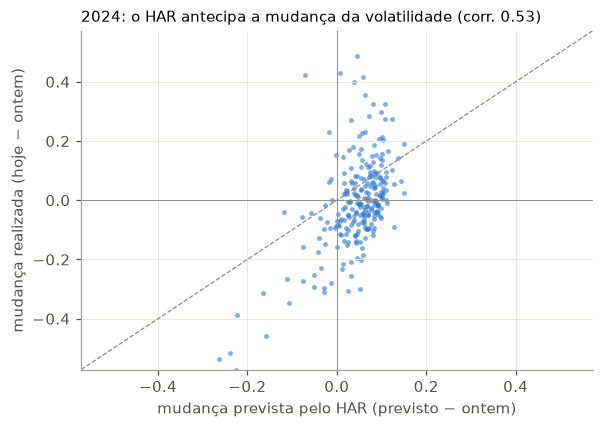

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(graf.mud_prev, graf.mud_real, s=10, color=AZUL, alpha=0.6, linewidths=0)
lim = np.nanpercentile(np.abs(graf.values), 99)
ax.plot([-lim, lim], [-lim, lim], color=CINZA, lw=0.8, ls="--")
ax.axhline(0, color=CINZA, lw=0.6); ax.axvline(0, color=CINZA, lw=0.6)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("mudança prevista pelo HAR (previsto − ontem)"); ax.set_ylabel("mudança realizada (hoje − ontem)")
ax.set_title(f"2024: o HAR antecipa a mudança da volatilidade (corr. {graf.mud_prev.corr(graf.mud_real):.2f})", loc="left", fontsize=10)
plt.show()

**Leitura:**

- O HAR tem correlação de **0,97–0,99 com o valor de ontem**: é, quase literalmente, "ontem suavizado". O deslocamento que você notou no gráfico é real.
- Em **nível**, a correlação do HAR com o alvo (0,46–0,71) mal passa a de "repetir ontem" (0,44–0,68). Pelo critério de correlação em nível, os dois pareceriam quase iguais.
- Nas **mudanças**, aparece a habilidade de verdade: o HAR antecipa se a volatilidade vai subir ou descer em relação a ontem (correlação de 0,45–0,53; acerta o sentido em 56–64% dos dias) e reduz o erro em ~19% contra "repetir ontem", em todos os anos. Ele sabe que, depois de um dia agitado, a volatilidade tende a voltar para a média da semana e do mês. No gráfico, as mudanças previstas são menores que as realizadas (a previsão de MSE encolhe; Seção 3.2) e, em 2024, ficam deslocadas para cima: o modelo, treinado em anos mais voláteis, espera a volatilidade voltar a um nível mais alto.

**A versão precisa da ideia do professor:** medir a correlação **na parte que não é óbvia**. Para preço e volatilidade, isso quer dizer as **mudanças**; para o retorno (o alvo do projeto), o próprio retorno, ou seja, o **IC**. Nos modelos de direção da Seção 2, o IC fica em ≈ 0.

**E para treinar?** Num modelo linear (ARIMA, regressão), minimizar o MSE já maximiza a correlação dentro da amostra; trocar o objetivo só muda a escala. Onde o objetivo faz diferença: em modelos não lineares (árvores, redes) e com dados de volatilidade muito variável, em que o MSE fica dominado pelos candles mais agitados (abertura, dias de notícia). Um remédio prático é treinar no **retorno dividido pela volatilidade prevista** (Estudo 07): cada candle passa a pesar igual, e o alvo vira "retorno em unidades de risco". Também ajuda a correlação de postos (Spearman), menos sensível a extremos.

## 4. "Acertar pouco e ganhar muito"

A esperança por operação (o critério do projeto desde o início) é:

$$E = p\cdot G - (1 - p)\cdot L - c$$

com p a taxa de acerto, G o ganho médio, L a perda média e c o custo. Uma taxa de acerto baixa não é problema se G/L (o *payoff*) for alto. O relatório original já mostrava isso: a melhor regra na validação acertava 48,7%.

**O cuidado:** mudar só as **saídas** (alvo e stop) **não cria vantagem**. Se a direção do preço é imprevisível, nenhuma regra de saída muda a esperança antes do custo; ela só redistribui os resultados entre muitos ganhos pequenos ou poucos ganhos grandes. Em probabilidade, isso é o **teorema da parada opcional** (*optional stopping*) para martingais.

Teste: **entradas aleatórias** nos candles de 60 min de 2024, com quatro regras de saída (200 sorteios cada; TP e SL em múltiplos da volatilidade recente, como no simulador).

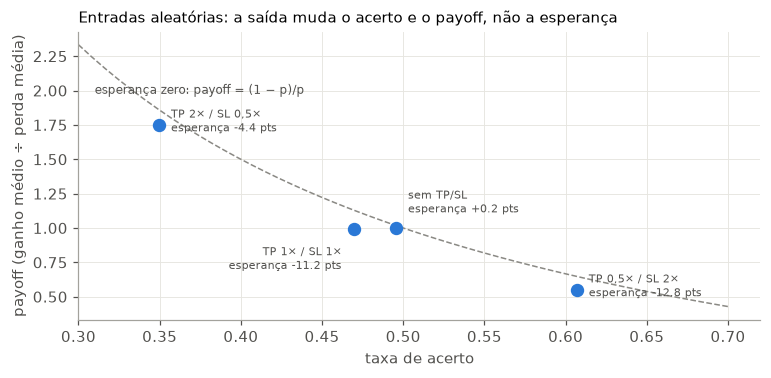

,taxa de acerto,ganho médio (pts),perda média (pts),payoff (G/L),esperança antes do custo (pts),variação entre sorteios (pts)
regra de saída,,,,,,
sem TP/SL,0.50,210.41,-209.84,1.00,0.22,6.14
TP 1× / SL 1×,0.47,183.57,-185.22,0.99,-11.21,4.57
"TP 2× / SL 0,5× (acerta pouco, ganha muito)",0.35,217.63,-124.51,1.75,-4.39,3.77
"TP 0,5× / SL 2× (acerta muito, ganha pouco)",0.61,125.79,-229.44,0.55,-12.83,3.96


In [9]:
p60 = pd.read_csv(f"{PASTA}/resultados/estatistico/previsoes/WIN_60min_6m_arima_val.csv", index_col=0, parse_dates=True)
regras = {"sem TP/SL": (None, None), "TP 1× / SL 1×": (1.0, 1.0),
          "TP 2× / SL 0,5× (acerta pouco, ganha muito)": (2.0, 0.5), "TP 0,5× / SL 2× (acerta muito, ganha pouco)": (0.5, 2.0)}
linhas = []
for nome, (tp, sl) in regras.items():
    acc, ganho, perda, esp = [], [], [], []
    for s in range(200):
        sinal = np.random.default_rng(s).choice([-1.0, 1.0], len(p60))
        o = cu.simular(p60.assign(y_pred=sinal), 0, tp, sl, "base"); o = o[o.lado != 0].bruto
        acc.append((o > 0).mean()); ganho.append(o[o > 0].mean()); perda.append(o[o < 0].mean()); esp.append(o.mean())
    linhas.append({"regra de saída": nome, "taxa de acerto": np.mean(acc), "ganho médio (pts)": np.mean(ganho),
                   "perda média (pts)": np.mean(perda), "payoff (G/L)": -np.mean(ganho) / np.mean(perda),
                   "esperança antes do custo (pts)": np.mean(esp), "variação entre sorteios (pts)": np.std(esp)})
tab4 = pd.DataFrame(linhas).set_index("regra de saída")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.scatter(tab4["taxa de acerto"], tab4["payoff (G/L)"], s=60, color=AZUL, zorder=3)
desloc = {"sem TP/SL": ((8, 10), "left"), "TP 1× / SL 1×": ((-8, -26), "right")}
for nome, row in tab4.iterrows():
    xy, ha = desloc.get(nome, ((8, -4), "left"))
    ax.annotate(f"{nome.split(' (')[0]}\nesperança {row['esperança antes do custo (pts)']:+.1f} pts", (row["taxa de acerto"], row["payoff (G/L)"]),
                textcoords="offset points", xytext=xy, ha=ha, fontsize=7.5, color="#52514e")
pp = np.linspace(0.3, 0.7, 50); ax.plot(pp, (1 - pp) / pp, color=CINZA, ls="--", lw=1)
ax.text(0.31, (1 - 0.31) / 0.31 - 0.25, "esperança zero: payoff = (1 − p)/p", color="#52514e", fontsize=8)
ax.set_xlim(0.3, 0.72); ax.set_xlabel("taxa de acerto"); ax.set_ylabel("payoff (ganho médio ÷ perda média)")
ax.set_title("Entradas aleatórias: a saída muda o acerto e o payoff, não a esperança", loc="left", fontsize=10); plt.show()
tab4.round(2)

**Leitura:**

- A regra de saída leva a taxa de acerto de **35% a 61%** e o payoff de **0,55 a 1,75**, mas a esperança antes do custo **nunca fica positiva**. Todos os pontos ficam sobre ou abaixo da curva de esperança zero.
- Os valores negativos não vêm de "azar": são os atritos realistas do simulador. Quando TP e SL podem ter sido tocados no mesmo candle, conta o stop, e o TP só executa se o preço passar 1 tick além.
- **"Acertar pouco e ganhar muito" é um formato de resultado, não uma vantagem.** Ele só dá lucro se o modelo souber **quando** os movimentos grandes vão a seu favor: por exemplo, continuação depois de um rompimento, ou uma direção previsível nos momentos de alta volatilidade.

**O que os nossos estudos dizem sobre "detectar cenários com margem de ganho alta":**

- **O tamanho dos movimentos é previsível** (Estudos 05–07): abertura, dias agitados, depois de um movimento grande. Nesses cenários, o mesmo acerto renderia mais pontos e o custo pesaria menos (o ρ necessário cai; Estudo 06).
- **A direção nesses cenários não é previsível:** sem continuação nem reversão depois de movimentos grandes (Estudo 05), sem direção pelo gap (Estudo 03). Com contratos futuros, "movimento grande" é tanto ganho grande quanto perda grande. Lucrar só com o tamanho exige um instrumento com resultado assimétrico (por exemplo, opções compradas), fora do escopo.
- **Estratégias de poucos ganhos grandes são difíceis de validar:** o resultado depende de poucas operações, o erro-padrão é grande e o poder é baixo (Estudo 03). É preciso mais dados, *bootstrap* e checar a mediana e o resultado sem os extremos.

## 5. Como os estudos ajudam os modelos de previsão

| O que aprendemos | Como usar num modelo de previsão |
|---|---|
| A **direção** é quase ruído; o **tamanho** tem memória (Estudos 01, 05–07) | Prever o que é previsível: volatilidade, amplitude, \|retorno\|. Ou um modelo em **dois estágios**: volatilidade primeiro, depois a direção no retorno **dividido pela volatilidade prevista** |
| O MSE fica dominado pelos candles agitados e é cego a correlações pequenas (Seção 3) | Avaliar pelo **IC** (correlação, com erro-padrão robusto ou *bootstrap*); treinar no retorno padronizado; decidir por quantis da previsão |
| Correlação em nível engana em séries persistentes (Seção 3.3) | Comparar sempre com "repetir o último valor" e medir nas **mudanças** |
| Assimetria só na volatilidade (Seção 1) | Termos separados para quedas no modelo de volatilidade (efeito alavancagem) |
| O horário importa: perfil intradiário, fechamento, abertura (Estudos 04 e 07) | *Features* de "onde estamos no dia": hora, minutos até o fim, retorno acumulado do dia, volatilidade esperada daquela hora |
| Consenso amplifica, não cria (Seção 2) | Combinar modelos só depois que cada um mostrar IC > 0 sozinho, de preferência com informações diferentes |
| Saídas não criam vantagem (Seção 4) | Escolher TP/SL pela volatilidade prevista (Estudo 07), não para "melhorar" um modelo sem vantagem |
| O método e os dados enganam (Estudos 02, 03, 08) | Simulação com resposta conhecida, placebo, aleatório nos mesmos candles, custo de equilíbrio, Holm, pré-registro, validação única |

## 6. Conclusões

| Ideia do professor | O que os dados mostram |
|---|---|
| Altas e baixas são diferentes | **Na direção, não** (intradiário simétrico). **Na volatilidade, sim**: quedas aumentam mais a volatilidade seguinte (efeito alavancagem, z ≈ 2,5) |
| Dois modelos, entrar quando concordam | Amplifica habilidade que já existe; não cria. ARIMA e RF de 2024 quase não se correlacionam, mas nenhum tem habilidade, e concordando acertam 48–49% |
| Correlação em vez de erro | **Certo para retornos:** o MSE/Theil U enxerga mal correlações pequenas mas úteis; o IC é a métrica certa. **Com cuidado em séries persistentes:** correlação em nível também é dominada pela persistência, e o que mede habilidade é a correlação nas mudanças (o HAR passa nesse teste: 0,45–0,53) |
| Acertar pouco e ganhar muito | É um formato, não uma vantagem: com entradas aleatórias, as saídas mudam o acerto (35–61%) e o payoff (0,55–1,75), mas a esperança fica ≤ 0. Funciona se houver previsão de **quando** os movimentos grandes vão a favor |